# 04 - Red neuronal artificial (ANN) para Palmer Penguins

**Objetivo:** clasificar la especie de pingüino (Adelie, Chinstrap o Gentoo) con una red neuronal que use:
- función de activación **sigmoide**,
- función de pérdida **Binary Cross-Entropy**,
- un conjunto de **entrenamiento del 80 %** y uno de **prueba del 20 %**,
- y reportar la **matriz de confusión**.

Como hay 3 especies y la pérdida pedida es Binary Cross-Entropy, la especie se codifica en *one-hot* (3 columnas de 0/1). La capa de salida tiene 3 neuronas sigmoides: cada una estima la probabilidad de que el pingüino sea de esa especie, y Binary Cross-Entropy se aplica a cada salida. La especie predicha es la de mayor probabilidad.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

np.random.seed(42)
tf.random.set_seed(42)

I0000 00:00:1792992798.354628     223 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792992800.175384     223 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Carga de datos

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
print("Valores faltantes por columna:")
print(df.isna().sum())
print("\nConteo por especie:")
print(df["species"].value_counts())

Valores faltantes por columna:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Conteo por especie:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


## 2. Preprocesamiento

- Se eliminan las filas con valores faltantes.
- Variables de entrada: medidas del pico, aleta y masa corporal (numéricas), más isla y sexo codificados en *one-hot*.
- La variable objetivo `species` se codifica en *one-hot* (3 columnas), para usar 3 salidas sigmoides con Binary Cross-Entropy.

In [4]:
data = df.dropna().reset_index(drop=True)
print("Filas después de quitar faltantes:", len(data))

num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X = pd.get_dummies(data[num_cols + ["island", "sex"]], columns=["island", "sex"], dtype=float)

classes = sorted(data["species"].unique())          # ['Adelie', 'Chinstrap', 'Gentoo']
y_labels = data["species"].map({c: i for i, c in enumerate(classes)}).values
Y = keras.utils.to_categorical(y_labels, num_classes=len(classes))

print("Variables de entrada:", list(X.columns))
print("Clases:", classes)

Filas después de quitar faltantes: 333
Variables de entrada: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'island_Biscoe', 'island_Dream', 'island_Torgersen', 'sex_FEMALE', 'sex_MALE']
Clases: ['Adelie', 'Chinstrap', 'Gentoo']


## 3. Conjuntos de entrenamiento (80 %) y prueba (20 %)

La separación es estratificada para conservar la proporción de especies en ambos conjuntos. El escalador se ajusta **solo** con el conjunto de entrenamiento.

In [5]:
X_train, X_test, Y_train, Y_test, y_train, y_test = train_test_split(
    X.values, Y, y_labels, test_size=0.2, random_state=42, stratify=y_labels)

scaler = StandardScaler()
num_idx = [X.columns.get_loc(c) for c in num_cols]
X_train[:, num_idx] = scaler.fit_transform(X_train[:, num_idx])
X_test[:, num_idx] = scaler.transform(X_test[:, num_idx])

print("Entrenamiento:", X_train.shape[0], "muestras")
print("Prueba:       ", X_test.shape[0], "muestras")

Entrenamiento: 266 muestras
Prueba:        67 muestras


## 4. Arquitectura de la red

- Capa oculta 1: 16 neuronas, activación sigmoide
- Capa oculta 2: 8 neuronas, activación sigmoide
- Capa de salida: 3 neuronas, activación sigmoide (una por especie)
- Pérdida: Binary Cross-Entropy
- Optimizador: Adam

In [6]:
model = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(16, activation="sigmoid"),
    keras.layers.Dense(8, activation="sigmoid"),
    keras.layers.Dense(len(classes), activation="sigmoid"),
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),
              loss="binary_crossentropy",
              metrics=["binary_accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 323 (1.26 KB)

 Trainable params: 323 (1.26 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Entrenamiento

In [7]:
history = model.fit(X_train, Y_train,
                    epochs=150, batch_size=16,
                    validation_split=0.1, verbose=0)

print("Pérdida final (entrenamiento):", round(history.history["loss"][-1], 4))
print("Pérdida final (validación):   ", round(history.history["val_loss"][-1], 4))

Pérdida final (entrenamiento): 0.0009
Pérdida final (validación):    0.0008


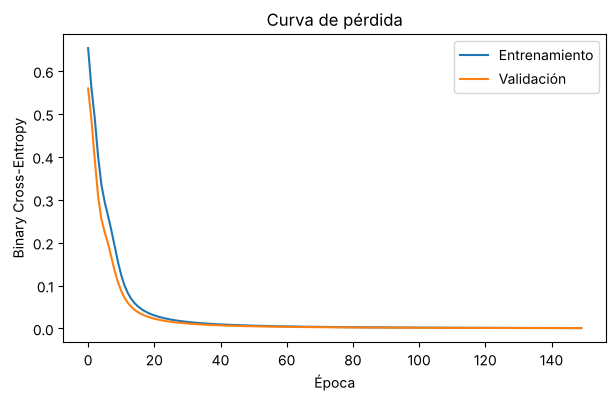

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history.history["loss"], label="Entrenamiento")
ax.plot(history.history["val_loss"], label="Validación")
ax.set_xlabel("Época")
ax.set_ylabel("Binary Cross-Entropy")
ax.set_title("Curva de pérdida")
ax.legend()
plt.show()

## 6. Evaluación en el conjunto de prueba

In [9]:
probs = model.predict(X_test, verbose=0)
y_pred = probs.argmax(axis=1)

print("Exactitud en prueba:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=classes, digits=3))

Exactitud en prueba: 1.0

              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        29
   Chinstrap      1.000     1.000     1.000        14
      Gentoo      1.000     1.000     1.000        24

    accuracy                          1.000        67
   macro avg      1.000     1.000     1.000        67
weighted avg      1.000     1.000     1.000        67



## 7. Matriz de confusión

                Pred Adelie  Pred Chinstrap  Pred Gentoo
Real Adelie              29               0            0
Real Chinstrap            0              14            0
Real Gentoo               0               0           24


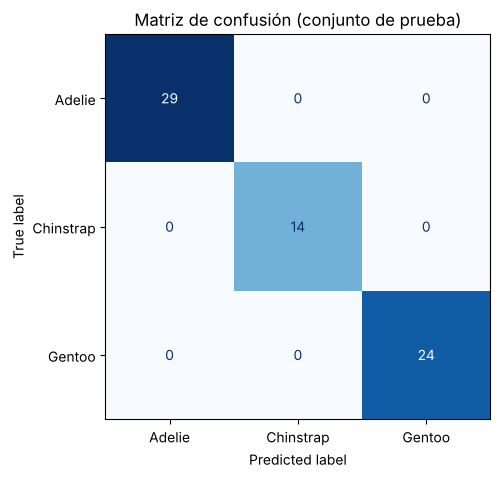

In [10]:
cm = confusion_matrix(y_test, y_pred)
print(pd.DataFrame(cm, index=[f"Real {c}" for c in classes], columns=[f"Pred {c}" for c in classes]))

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión (conjunto de prueba)")
plt.show()

## 8. Conclusiones

- La red, usando solo activaciones sigmoides y Binary Cross-Entropy, separa las tres especies con muy alta exactitud en el conjunto de prueba.
- La matriz de confusión muestra en la diagonal los aciertos de cada especie; los valores fuera de la diagonal son las confusiones.
- Gentoo es la especie más fácil de distinguir (es más grande y con aletas más largas). Los errores, cuando aparecen, suelen ser entre Adelie y Chinstrap, que tienen tamaños parecidos y se distinguen sobre todo por la longitud del pico.